# **(1) Carga de librerias**

In [1]:
import scanpy as sc              # análisis single-cell principal
import pandas as pd              # manejo de CSV
import numpy as np

import matplotlib.pyplot as plt  # visualización básica
import seaborn as sns            # plots estadísticos

# **Working directory**

In [21]:
import os

os.chdir("/home/vant/Documentos/A/Academico/MsC/Practicas/TFM")

# **(2) Carga de datos (Matthys)**

In [2]:
# 2.1 cargar matriz single-cell
#adata = sc.read_h5ad("../data/organized_data/human/brain/matthys/sample.h5ad")

# 2.2 cargar metadata externa (CSV clínico o técnico)
meta = pd.read_csv("/home/vant/Documentos/A/Academico/MsC/Practicas/TFM/data/organized_data/human/brain/snRNA/matthys/SEAAD_A9_RNAseq_all-nuclei_metadata.2024-02-13.csv")

# inspección rápida
meta.head()

,exp_component_name,sample_id,Neurotypical reference,Donor ID,Organism,Brain Region,Sex,Gender,Age at Death,Race (choice=White),...,Fraction mitochondrial UMIs,Used in analysis,Class confidence,Class,Subclass confidence,Subclass,Supertype confidence,Supertype (non-expanded),Supertype,Severely Affected Donor
0,GGTAGAGCAACCAACT-L8TX_210902_01_B09-1128419134,GGTAGAGCAACCAACT-L8TX_210902_01_B09-1128419134,False,H21.33.003,human,Human DFC_all_layers,Male,Male,78.0,Unchecked,...,0.000185,True,1.000000,exc,1.000000,L2/3 IT,1.000000,L2/3 IT_5,L2/3 IT_5,N
1,AGTTAGCCACTTGTCC-L8TX_210826_01_F06-1127603906,AGTTAGCCACTTGTCC-L8TX_210826_01_F06-1127603906,False,H21.33.021,human,Human DFC_all_layers,Male,Female,99.0,Checked,...,0.002340,True,1.000000,exc,1.000000,L6 IT,1.000000,L6 IT_2,L6 IT_2,N
2,CGTAATGAGTTAGAAC-L8TX_211216_01_G03-1149532256,CGTAATGAGTTAGAAC-L8TX_211216_01_G03-1149532256,False,H20.33.032,human,Human DFC_all_layers,Male,Male,98.0,Checked,...,0.000820,True,1.000000,inh,1.000000,Pvalb,0.999997,Pvalb_14,Pvalb_14,N
3,CATCCACGTACCACGC-L8TX_220217_01_H04-1162250581,CATCCACGTACCACGC-L8TX_220217_01_H04-1162250581,False,H21.33.003,human,Human DFC_all_layers,Male,Male,78.0,Unchecked,...,0.000675,False,1.000000,inh,0.916959,Pax6,0.999275,Pax6_4,cluster_doublet_score_flag,N
4,TCTAACTTCCCAGGAC-L8TX_210902_01_F09-1129993893,TCTAACTTCCCAGGAC-L8TX_210902_01_F09-1129993893,False,H20.33.036,human,Human DFC_all_layers,Female,Female,100.0,Checked,...,0.015767,False,0.999996,glia,0.973951,OPC,1.000000,OPC_2,nFeature_RNA,N


# **(3) Análisis exploratorio general**

In [3]:
# tamaño del dataset
print(meta.shape)

# columnas
meta.columns

# tipos de datos
meta.info()

summary = pd.DataFrame({
    "Metric": [
        "Number of rows (cells)",
        "Number of columns (features)",
        "Memory usage"
    ],
    "Value": [
        meta.shape[0],
        meta.shape[1],
        f"{meta.memory_usage(deep=True).sum() / 1e6:.2f} MB"
    ]
})

summary

(1831132, 133)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1831132 entries, 0 to 1831131
Columns: 133 entries, exp_component_name to Severely Affected Donor
dtypes: bool(3), float64(63), int64(5), object(62)
memory usage: 1.8+ GB


,Metric,Value
0,Number of rows (cells),1831132
1,Number of columns (features),133
2,Memory usage,8325.72 MB


## **Valores nulos**

In [4]:
# valores nulos
meta.isnull().sum()

exp_component_name              0
sample_id                       0
Neurotypical reference          0
Donor ID                        0
Organism                        0
                            ...  
Subclass                        0
Supertype confidence            0
Supertype (non-expanded)        0
Supertype                       0
Severely Affected Donor     94928
Length: 133, dtype: int64

## **Duplicados**

In [5]:
# duplicados
meta.duplicated().sum()

np.int64(0)

## **Columnas "sin información"**
### - No separan pacientes
### - No explican biología
### - No ayudan a clustering
### - Los datos son los mismo pàra la columna completa

In [6]:
# columnas constantes (sin información)
[col for col in meta.columns if meta[col].nunique() == 1]

['Organism',
 'Brain Region',
 'cell_prep_type',
 'rna_amplification_pass_fail',
 'library_prep_pass_fail',
 'Genome']

# **(4) Comprender variables biológica sy técnicas**

In [7]:
for col in meta.columns:
    print("\n", col)
    print(meta[col].value_counts().head())


 exp_component_name
exp_component_name
GGTAGAGCAACCAACT-L8TX_210902_01_B09-1128419134    1
AGTTAGCCACTTGTCC-L8TX_210826_01_F06-1127603906    1
CGTAATGAGTTAGAAC-L8TX_211216_01_G03-1149532256    1
CATCCACGTACCACGC-L8TX_220217_01_H04-1162250581    1
TCTAACTTCCCAGGAC-L8TX_210902_01_F09-1129993893    1
Name: count, dtype: int64

 sample_id
sample_id
GGTAGAGCAACCAACT-L8TX_210902_01_B09-1128419134    1
AGTTAGCCACTTGTCC-L8TX_210826_01_F06-1127603906    1
CGTAATGAGTTAGAAC-L8TX_211216_01_G03-1149532256    1
CATCCACGTACCACGC-L8TX_220217_01_H04-1162250581    1
TCTAACTTCCCAGGAC-L8TX_210902_01_F09-1129993893    1
Name: count, dtype: int64

 Neurotypical reference
Neurotypical reference
False    1736204
True       94928
Name: count, dtype: int64

 Donor ID
Donor ID
H21.33.003    56682
H20.33.015    37295
H19.30.002    34508
H21.33.001    32600
H21.33.002    31617
Name: count, dtype: int64

 Organism
Organism
human    1831132
Name: count, dtype: int64

 Brain Region
Brain Region
Human DFC_all_layers 

## **Distribución numérica**

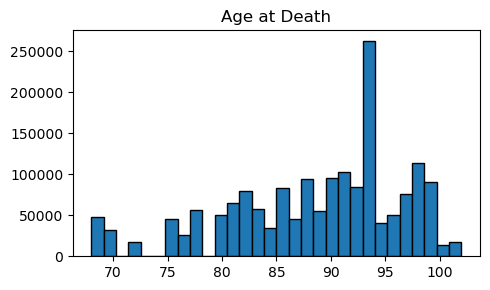

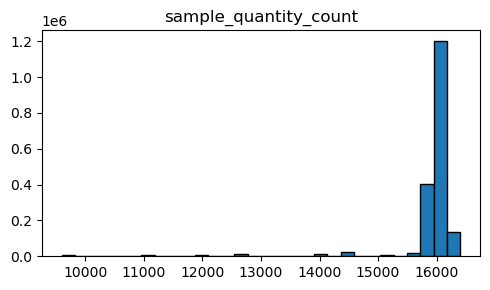

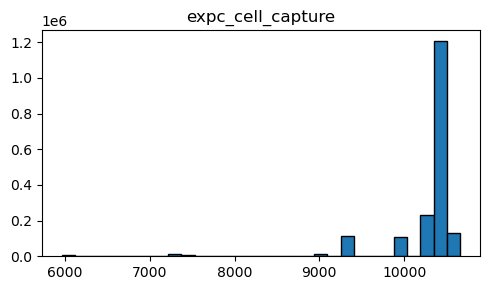

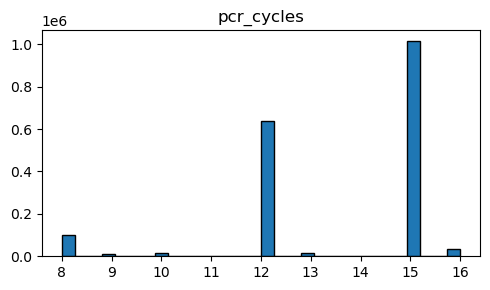

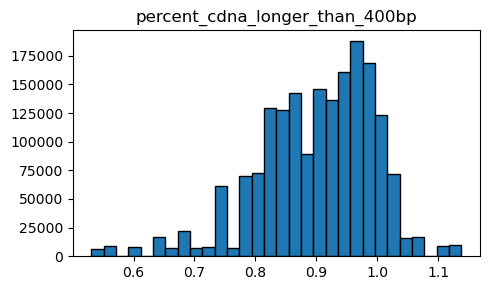

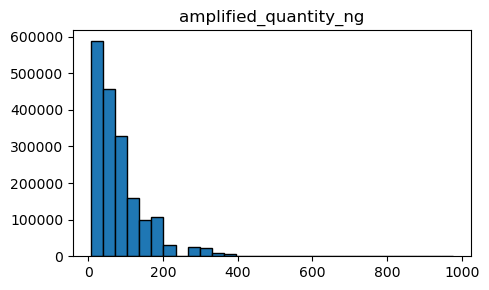

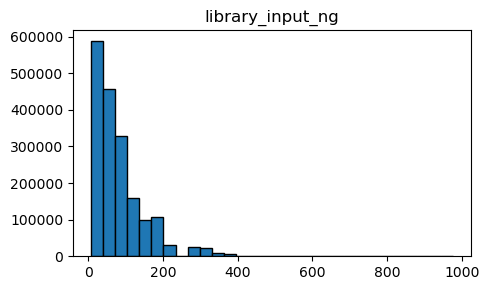

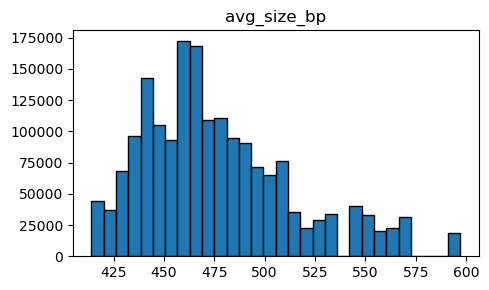

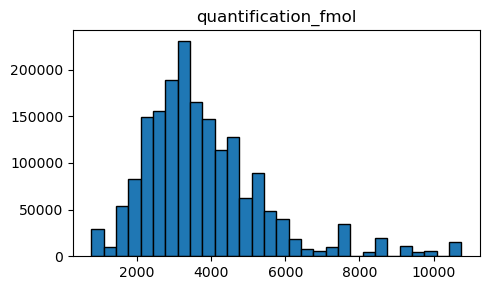

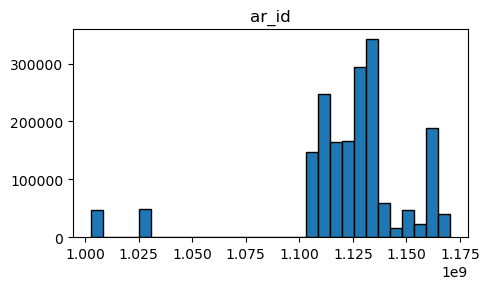

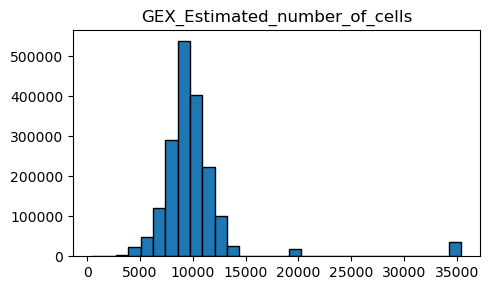

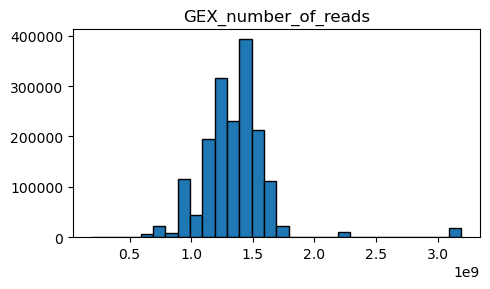

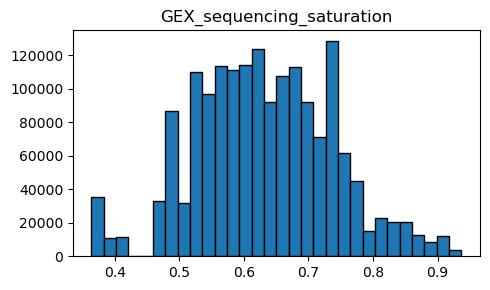

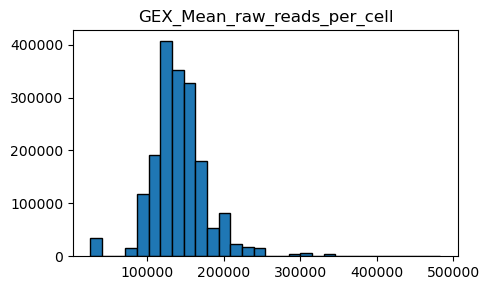

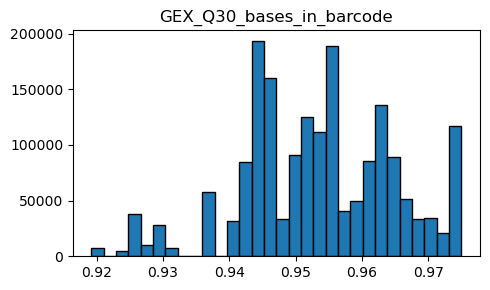

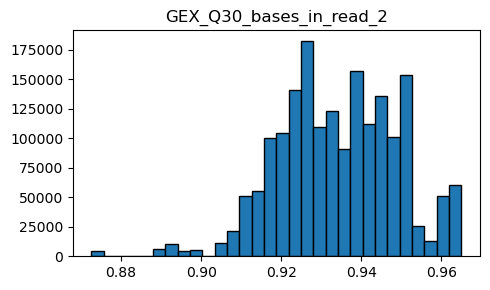

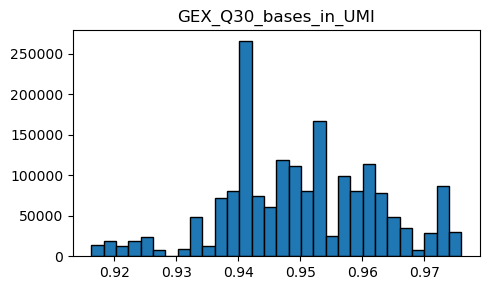

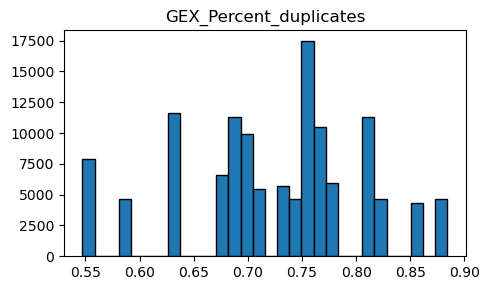

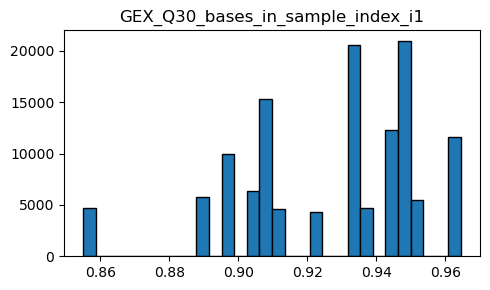

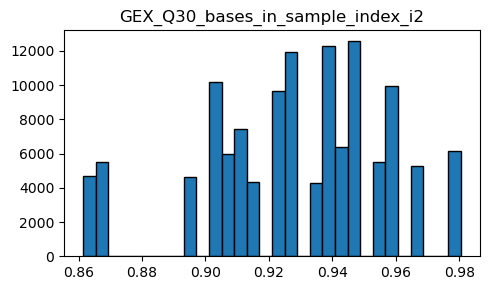

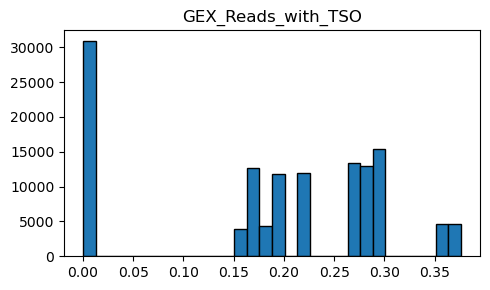

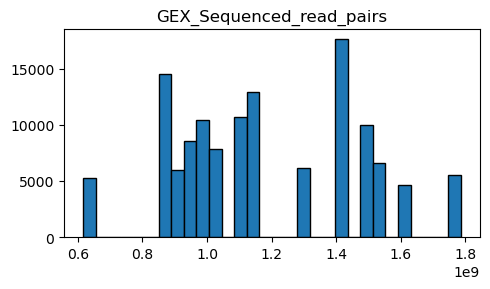

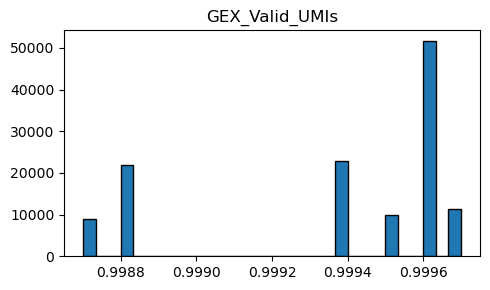

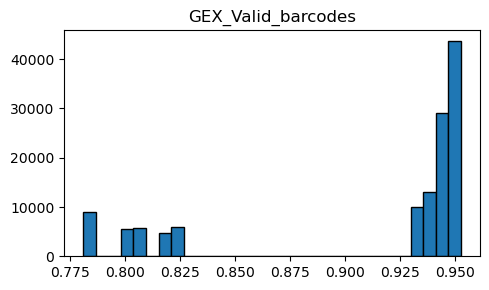

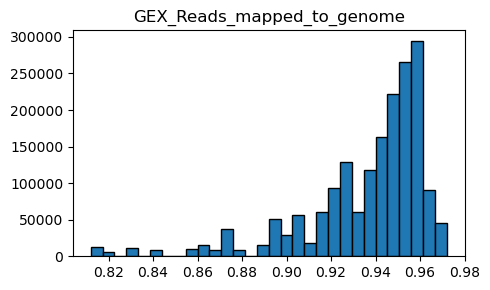

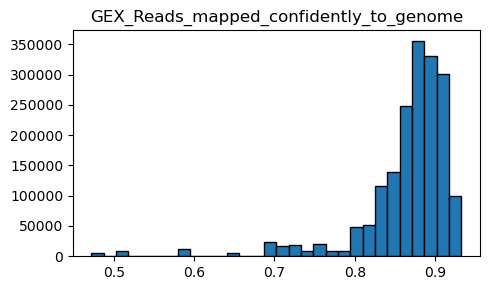

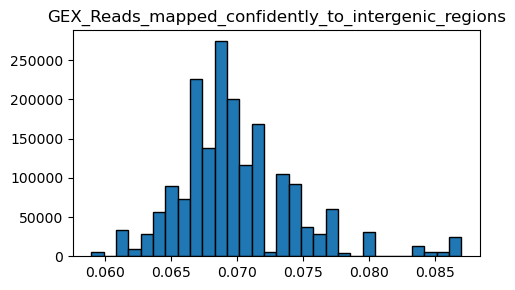

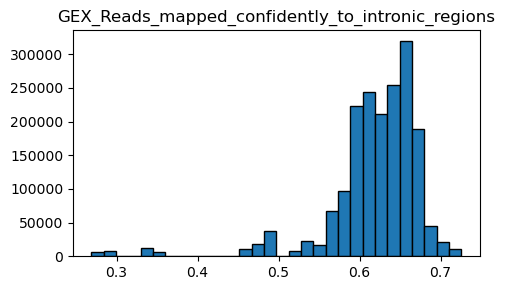

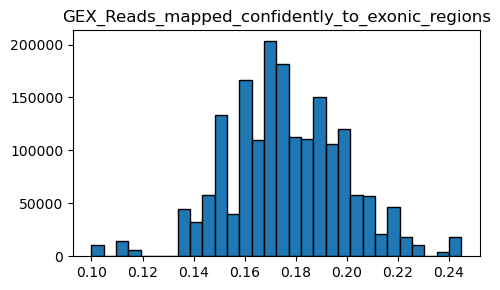

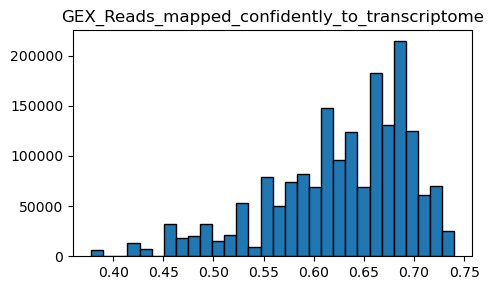

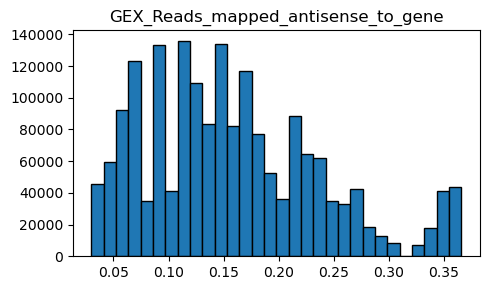

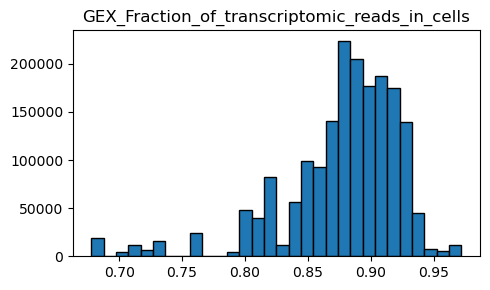

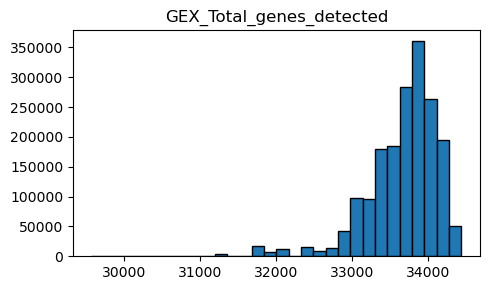

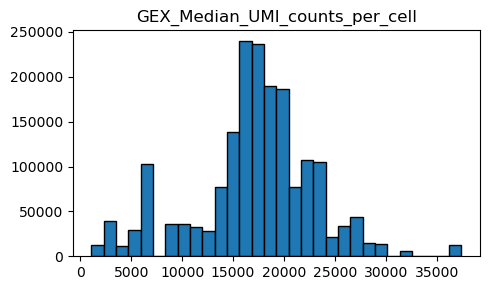

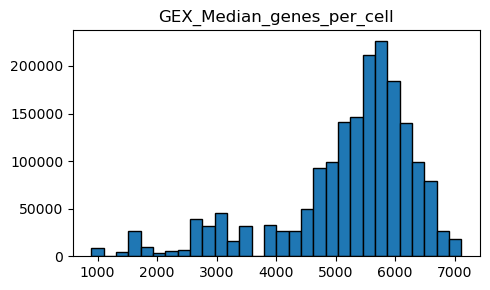

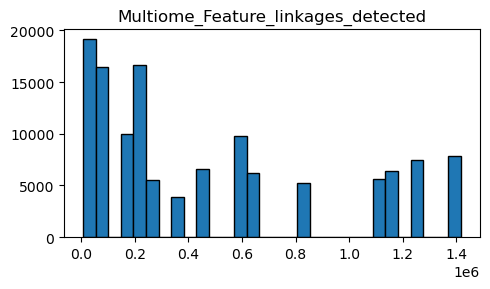

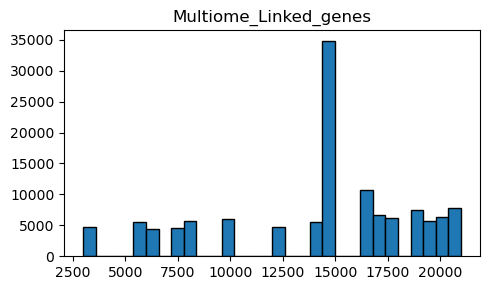

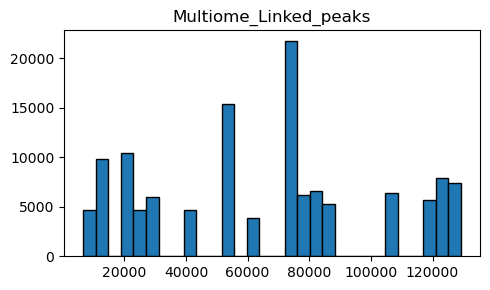

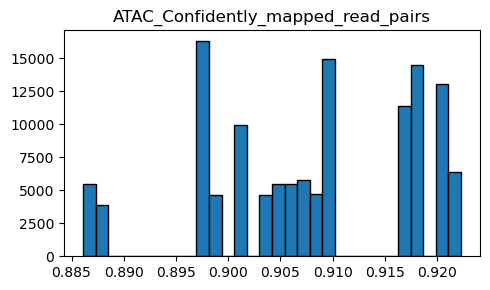

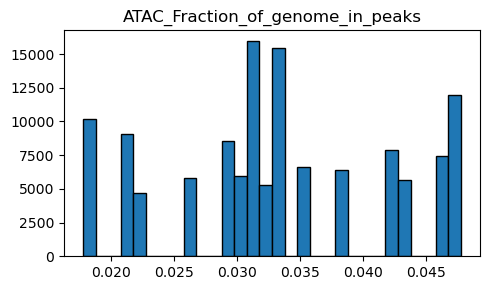

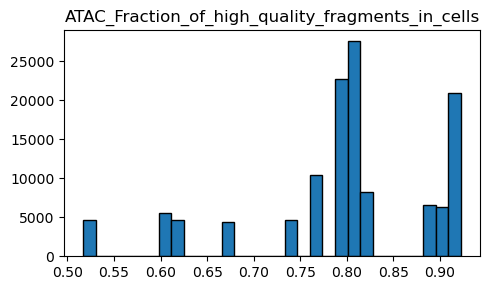

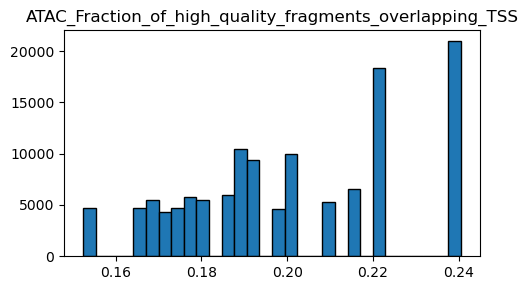

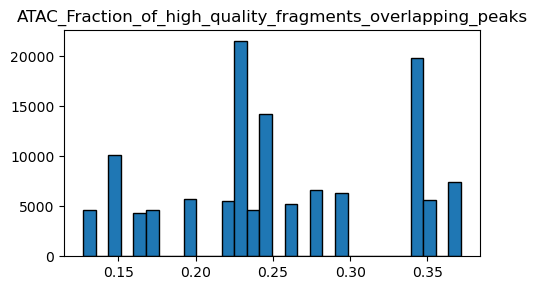

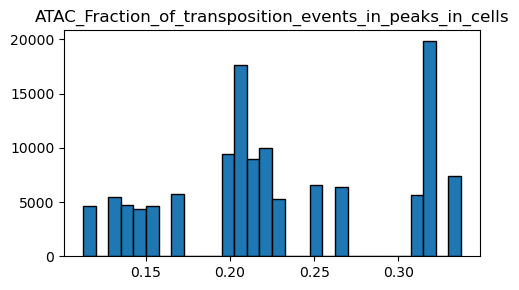

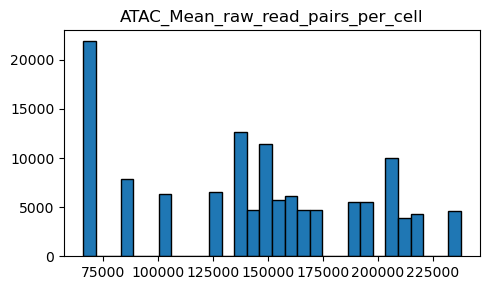

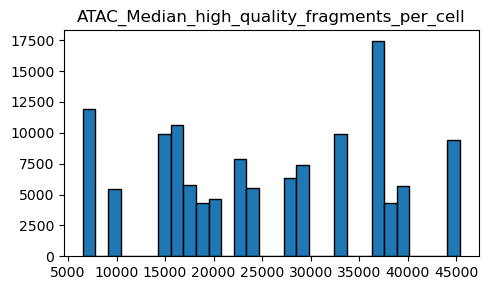

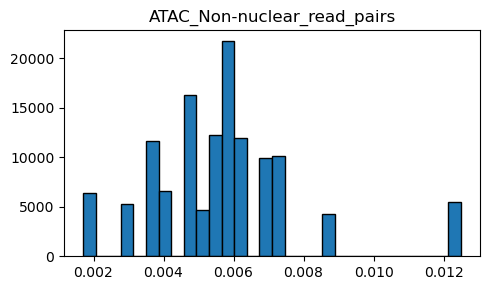

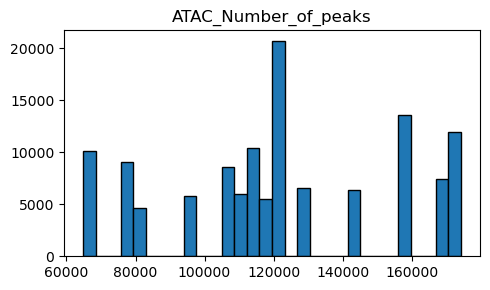

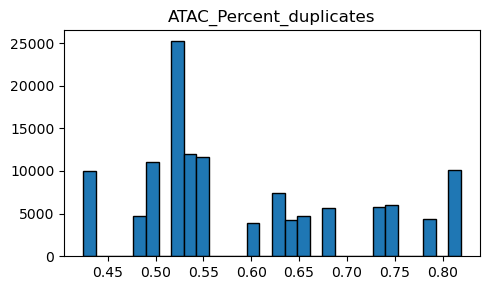

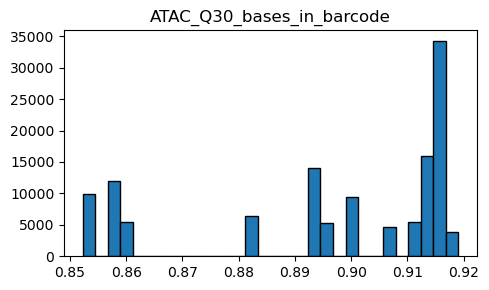

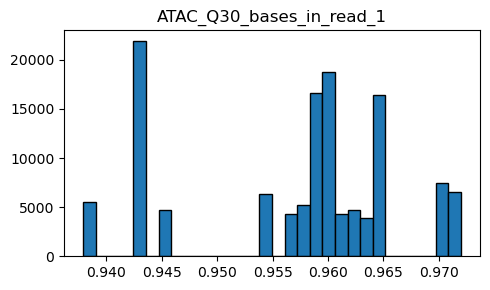

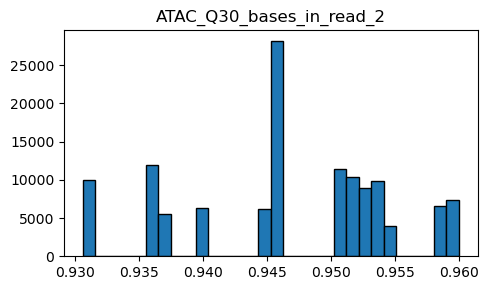

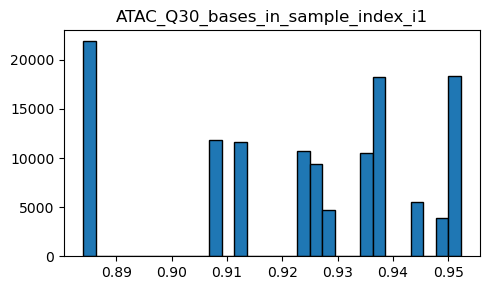

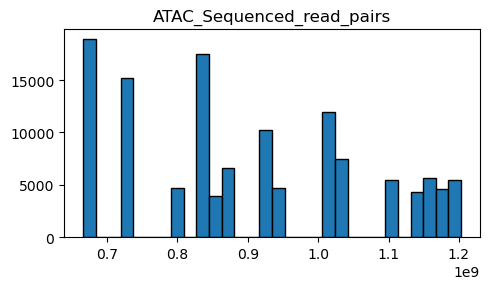

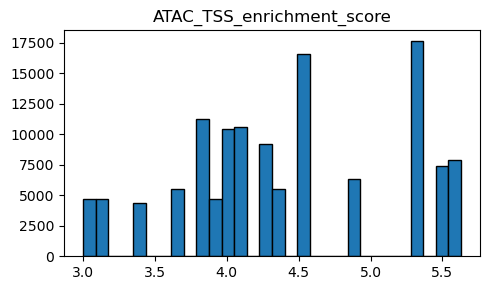

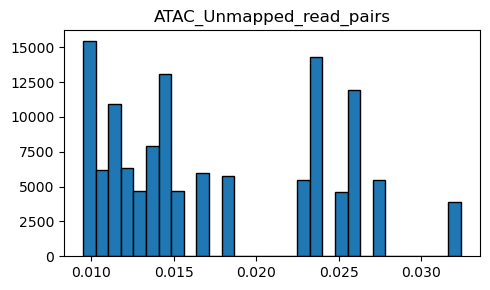

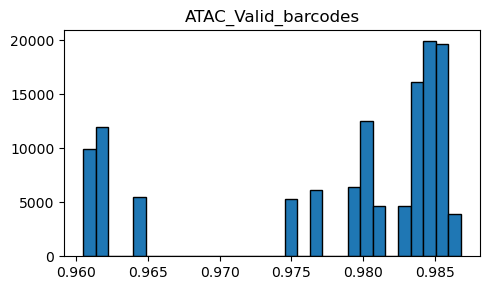

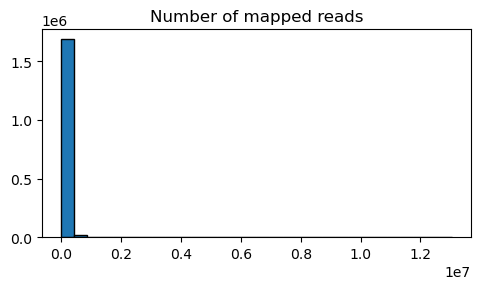

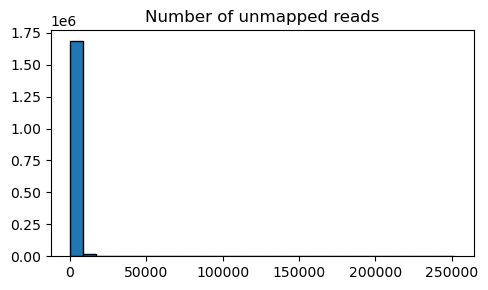

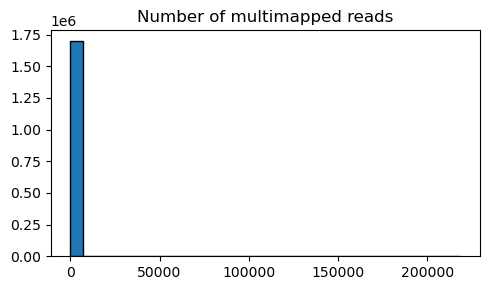

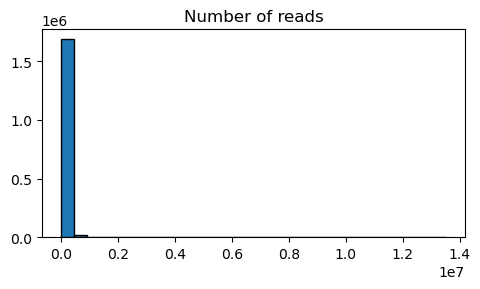

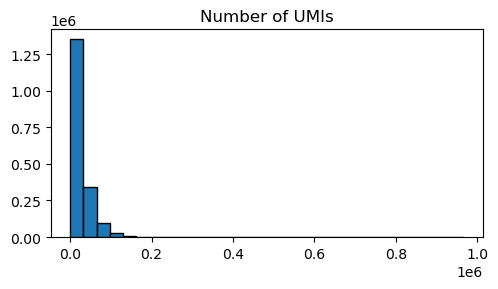

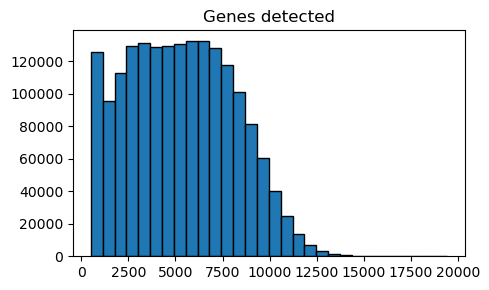

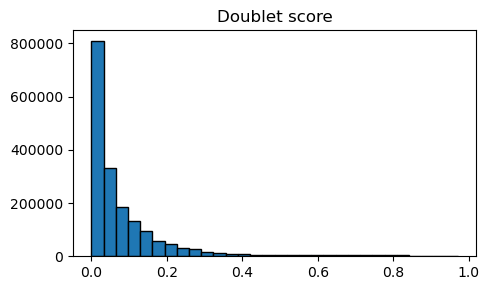

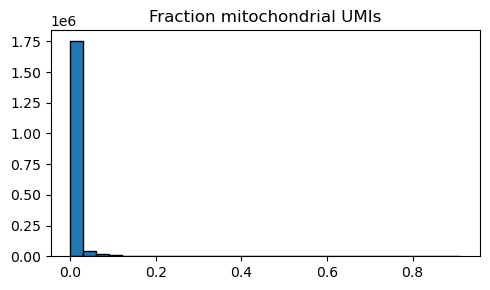

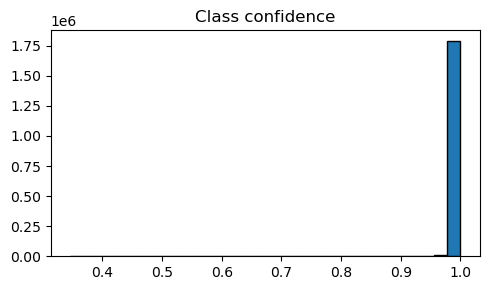

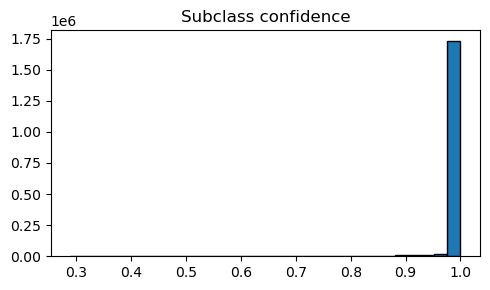

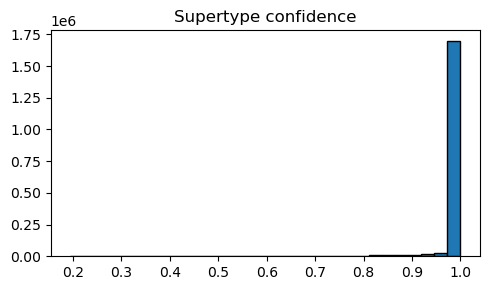

In [9]:
num_cols = meta.select_dtypes(include="number").columns
for col in num_cols:
    plt.figure(figsize=(5, 3))
    plt.hist(meta[col], bins=30, edgecolor="black")
    plt.title(col)
    plt.tight_layout()
    plt.show()

## **Variables categóricas**

In [10]:
cat_cols = meta.select_dtypes(include="object").columns

for col in cat_cols[:5]:
    plt.figure()
    sns.countplot(data=meta, x=col)
    plt.xticks(rotation=45)
    plt.title(col)
    plt.show()

KeyboardInterrupt: 

Error in callback <function _draw_all_if_interactive at 0x708980fb7ec0> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

Error in callback <function flush_figures at 0x70897ed08680> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

In [12]:
cat_cols = [
    col for col in meta.select_dtypes(include="object").columns
    if meta[col].nunique() < 20
]

cat_cols

['Organism',
 'Brain Region',
 'Sex',
 'Gender',
 'Race (choice=White)',
 'Race (choice=Black/ African American)',
 'Race (choice=Asian)',
 'Race (choice=American Indian/ Alaska Native)',
 'Race (choice=Native Hawaiian or Pacific Islander)',
 'Race (choice=Unknown or unreported)',
 'Race (choice=Other)',
 'specify other race',
 'Hispanic/Latino',
 'Highest level of education',
 'Years of education',
 'Brain pH',
 'Overall AD neuropathological Change',
 'Thal',
 'Braak',
 'CERAD score',
 'Overall CAA Score',
 'Highest Lewy Body Disease',
 'Total Microinfarcts (not observed grossly)',
 'Total microinfarcts in screening sections',
 'Atherosclerosis',
 'Arteriolosclerosis',
 'LATE',
 'Cognitive Status',
 'Last MMSE Score',
 'Last MOCA Score',
 'Interval from last MOCA in months',
 'APOE Genotype',
 'Primary Study Name',
 'Secondary Study Name',
 'cell_prep_type',
 'facs_population_plan',
 'method',
 'rna_amplification_pass_fail',
 'library_prep_pass_fail',
 'alignment',
 'Genome',
 'Class'

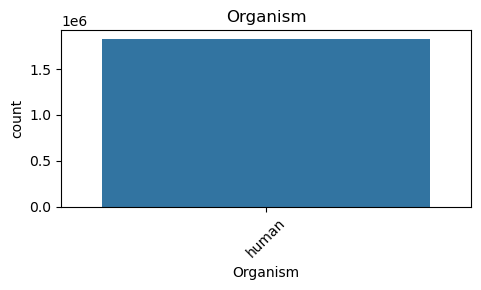

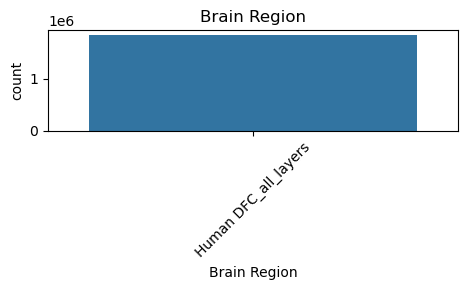

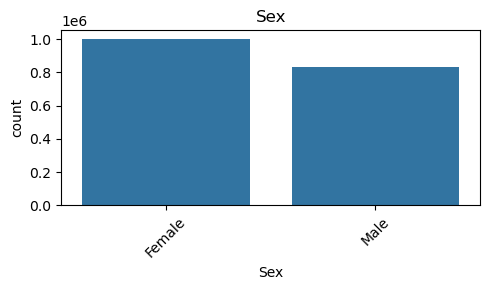

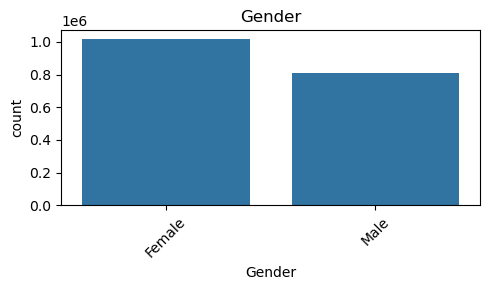

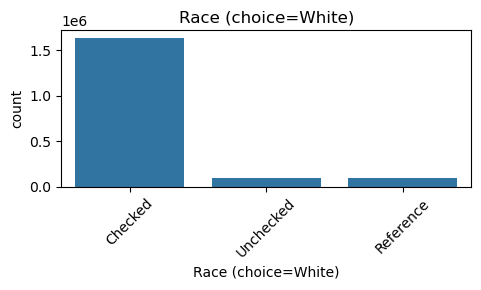

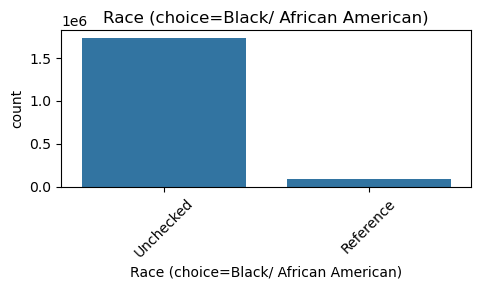

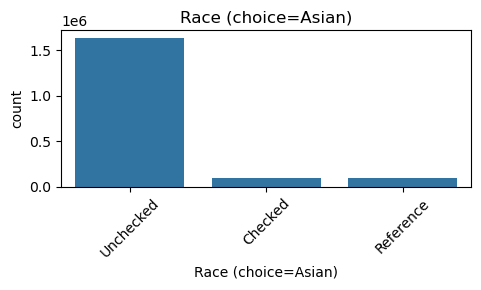

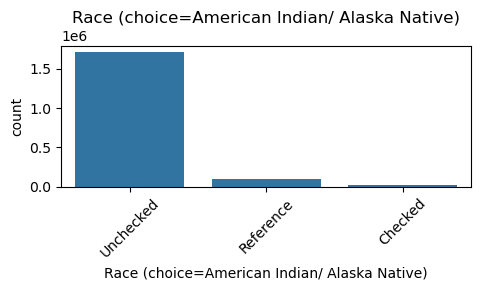

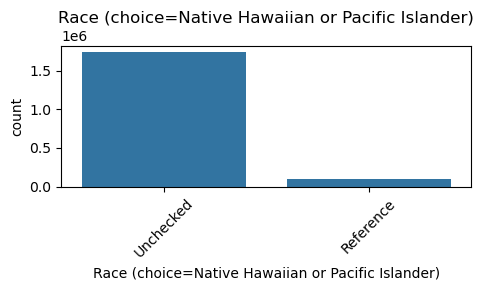

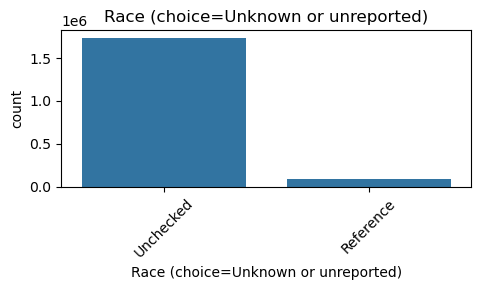

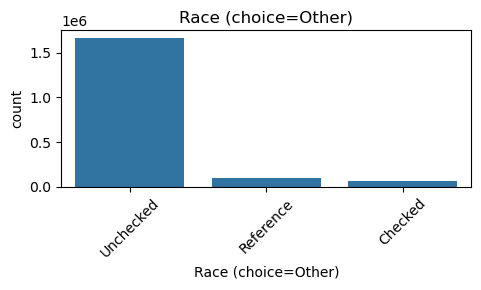

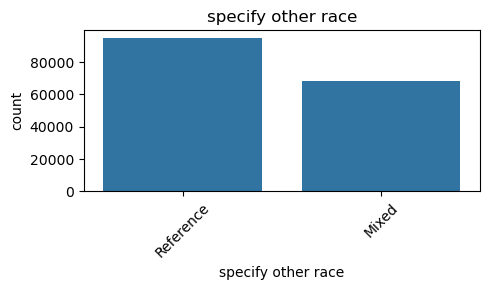

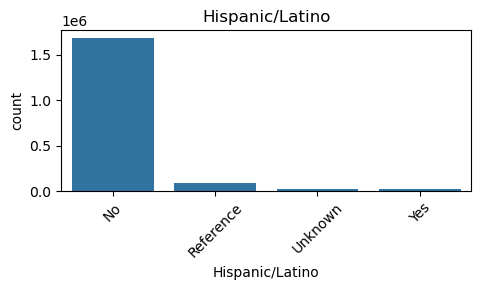

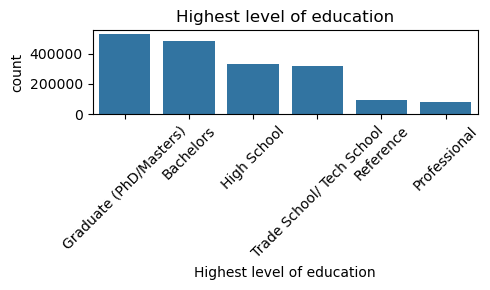

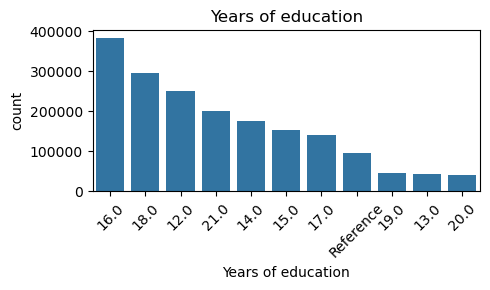

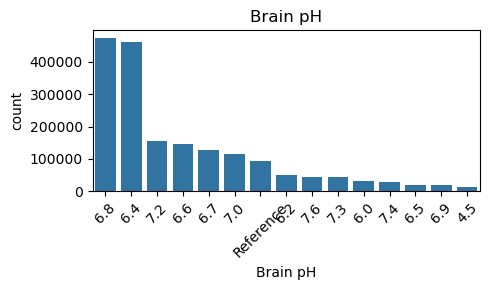

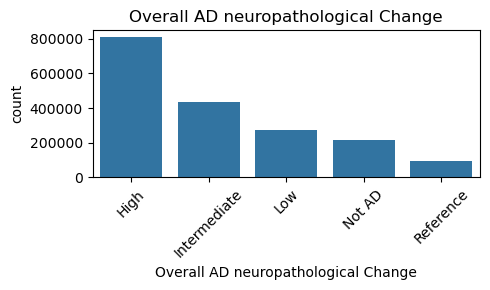

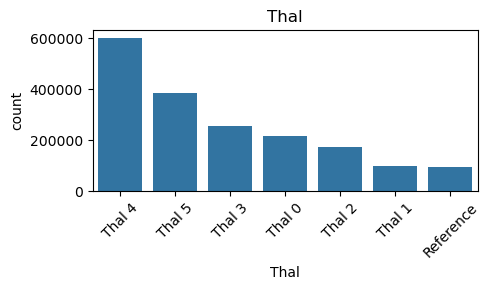

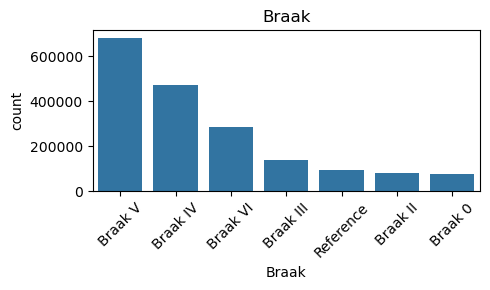

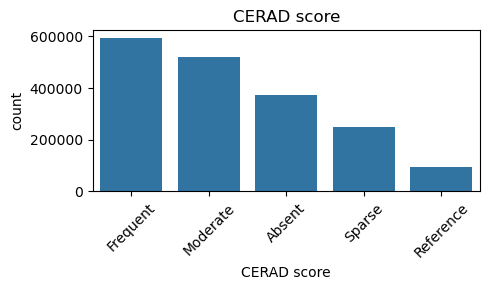

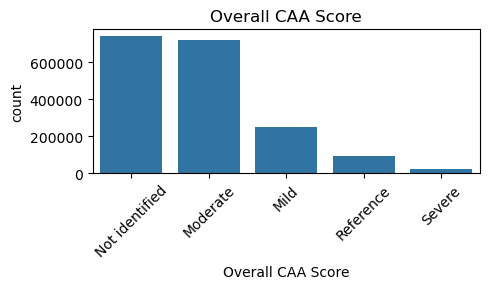

/tmp/ipykernel_45217/276784066.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


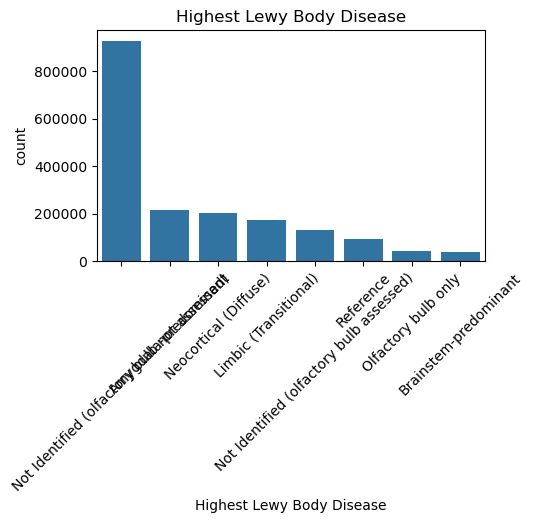

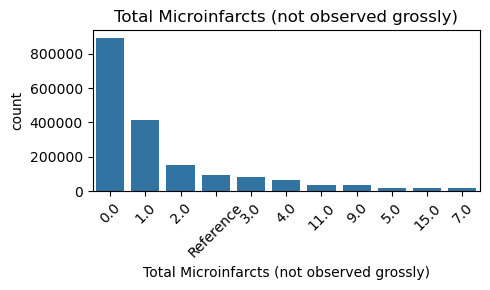

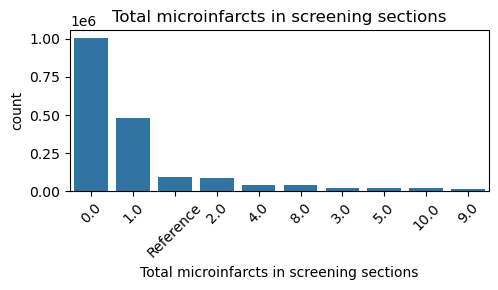

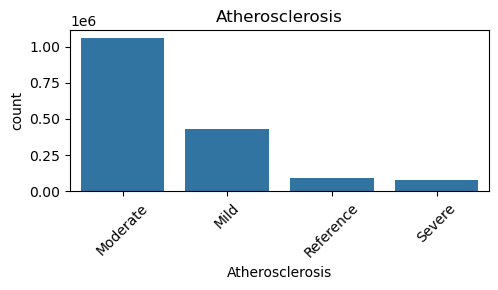

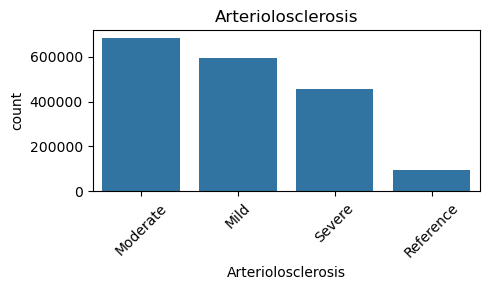

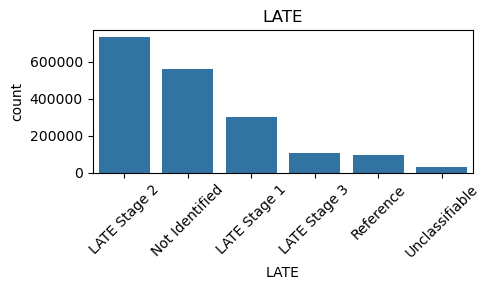

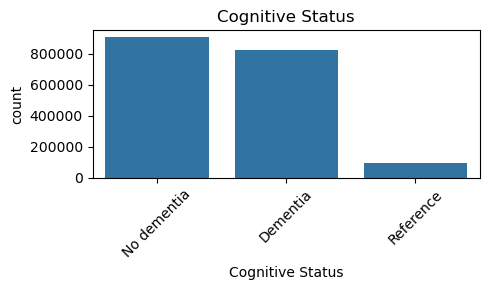

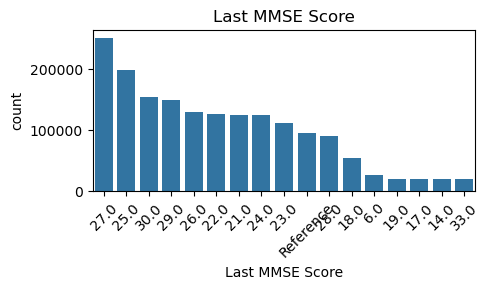

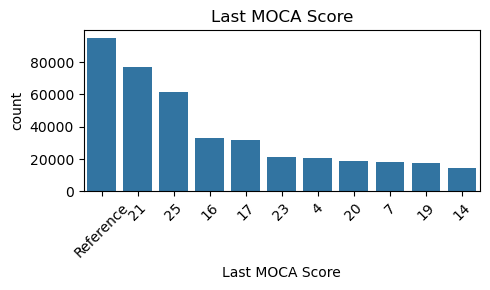

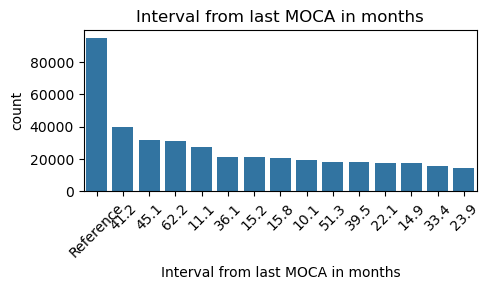

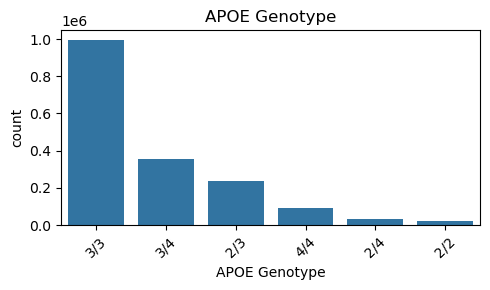

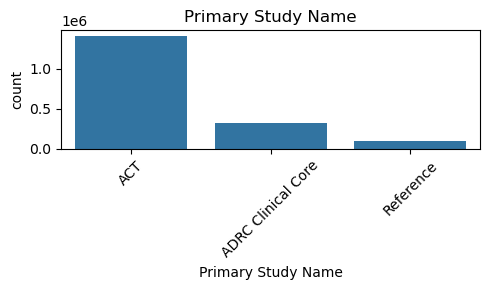

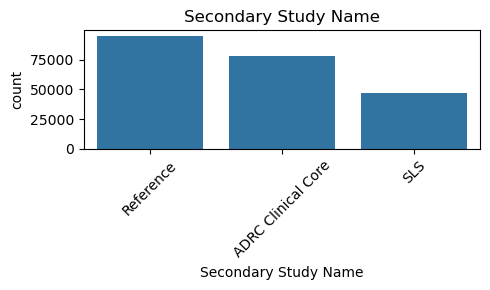

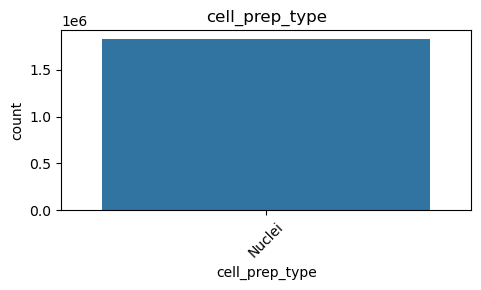

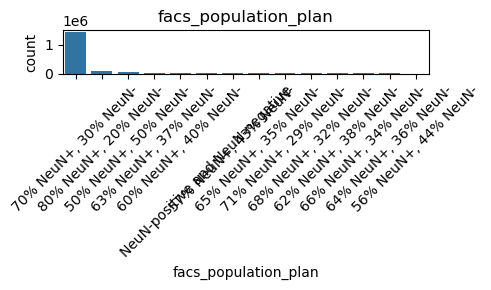

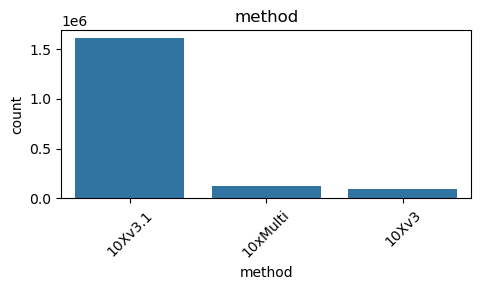

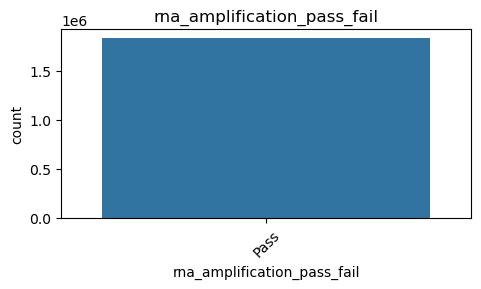

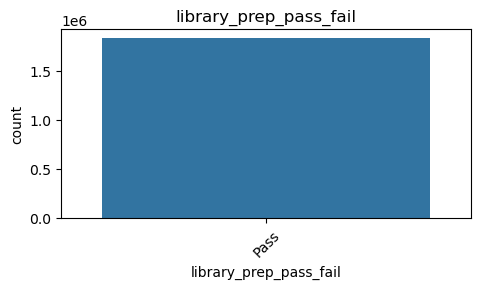

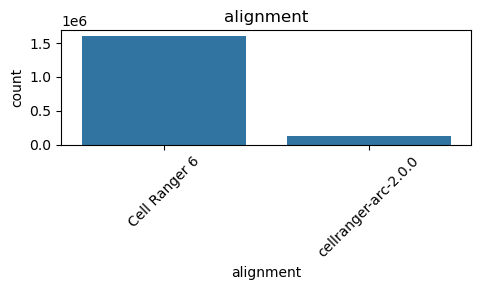

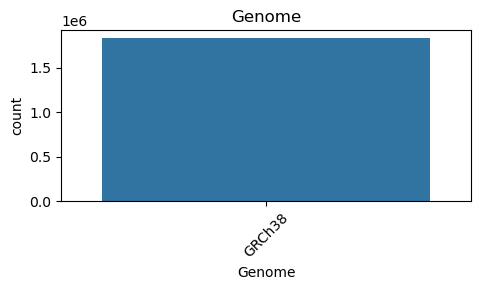

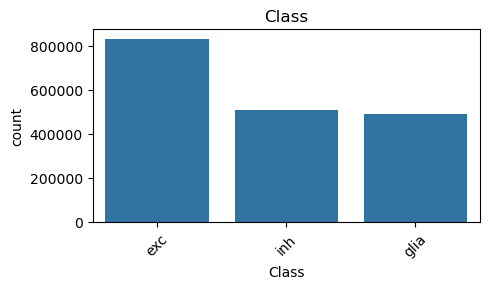

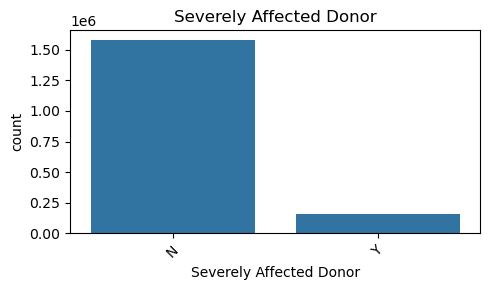

In [13]:
for col in cat_cols:

    plt.figure(figsize=(5,3))

    sns.countplot(
        data=meta,
        x=col,
        order=meta[col].value_counts().index
    )

    plt.xticks(rotation=45)
    plt.title(col)

    plt.tight_layout()
    plt.show()

# **Exportación de la matriz de expresión para RaceID**

La exportación de la matriz de expresión en análisis de datos single-cell consiste en convertir la estructura interna de un objeto como `AnnData` de Scanpy en una tabla legible y almacenada en disco, normalmente en formato CSV. Este proceso se realiza típicamente con `adata.to_df().to_csv("counts.csv")`. Primero, `adata.to_df()` extrae la matriz de expresión almacenada en `adata.X` y la transforma en un `DataFrame` de pandas, donde cada fila representa una célula y cada columna representa un gen. Los valores de la matriz corresponden a los niveles de expresión génica medidos en cada célula. Posteriormente, `.to_csv("counts.csv")` guarda esta tabla en un archivo CSV, permitiendo su uso fuera de Python. Esta exportación es un paso clave en pipelines bioinformáticos porque muchas herramientas externas, como RaceID en R, no pueden leer directamente el formato `.h5ad` y requieren matrices tabulares de expresión como entrada para realizar análisis como clustering o detección de células raras.